# 01 · Faixas dos coeficientes do CROPGRO-Soybean

Define o espaço de busca da análise de sensibilidade (etapa 02) e, depois, as distribuições a priori da calibração.

**Regra:** a faixa de cada coeficiente é a envoltória de três fontes:
1. linhas `MINIMA`/`MAXIMA` do `SBGRO048.CUL` (faixas do GENCALC);
2. grupos genéricos e cultivares do `.CUL`/`.ECO` com MG entre 5 e 10 (faixa brasileira);
3. coeficientes publicados para cultivares brasileiras (`dados/literatura/coeficientes_literatura.csv`).

Entram os coeficientes marcados como **P** (fenologia) e **G** (crescimento) no `.CUL`, mais `FL-VS` e `R1PPO` do `.ECO`, que mudam com o hábito de crescimento e o MG.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", message=".*DSSATTools version.*")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from genotipo import tabela_genotipos, limites_dssat
from faixas import calcular_faixas, ler_literatura, COEF_ANALISE

/Users/coted-sh/Python/DSSAT/calibracao_mg/.venv/lib/python3.11/site-packages/DSSATTools/__init__.py:105: DeprecationWarning: DSSATTools version 3.0.0 is a major upgrade and will not be backwards compatible with previous versions. If you are running code that was developed  using a previous DSSATTools version, then install DSSATTools version 2.1.6
  warnings.warn(


## Cultivares do SBGRO048.CUL com os parâmetros de ecótipo

In [2]:
gen = tabela_genotipos()
print("Ecótipos referenciados no .CUL mas ausentes do .ECO:",
      gen.loc[gen["ECO_AUSENTE"], ["VAR-NAME", "ECO#"]].to_dict("index"))
gen[["VAR-NAME", "ECO#", "MG", "GENERICO", *COEF_ANALISE]]

Ecótipos referenciados no .CUL mas ausentes do .ECO: {'RB0002': {'VAR-NAME': 'MG77PA (13)', 'ECO#': 'SB0777'}, 'RB0003': {'VAR-NAME': 'MG88PA (11)', 'ECO#': 'SB0888'}}


,VAR-NAME,ECO#,MG,GENERICO,CSDL,PPSEN,EM-FL,FL-SD,SD-PM,LFMAX,SLAVR,SIZLF,WTPSD,SFDUR,SDPDV,FL-VS,R1PPO
VAR#,,,,,,,,,,,,,,,,,
990011,M GROUP 000,SB0001,-2.0,True,14.60,0.129,15.50,12.00,29.5,1.030,375.0,180.0,0.190,23.0,2.20,26.0,0.189
990012,M GROUP 00,SB0001,-1.0,True,14.35,0.148,16.00,12.00,30.0,1.030,375.0,180.0,0.190,23.0,2.20,26.0,0.189
990013,M GROUP 0,SB0001,0.0,True,14.10,0.171,16.80,13.00,30.8,1.030,375.0,180.0,0.190,23.0,2.20,26.0,0.189
990001,M GROUP 1,SB0101,1.0,True,13.84,0.203,17.00,13.00,31.6,1.030,375.0,180.0,0.190,23.0,2.20,26.0,0.234
990002,M GROUP 2,SB0201,2.0,True,13.59,0.249,17.40,13.50,32.4,1.030,375.0,180.0,0.190,23.0,2.20,26.0,0.279
990003,M GROUP 3,SB0301,3.0,True,13.40,0.285,19.00,14.00,33.2,1.030,375.0,180.0,0.190,23.0,2.20,26.0,0.324
990004,M GROUP 4,SB0401,4.0,True,13.09,0.294,19.40,15.00,34.0,1.030,375.0,180.0,0.190,23.0,2.20,26.0,0.369
990005,M GROUP 5,SB0501,5.0,True,12.83,0.303,19.80,15.50,34.8,1.030,375.0,180.0,0.180,23.0,2.05,9.0,0.414
990006,M GROUP 6,SB0601,6.0,True,12.58,0.311,20.20,16.00,35.6,1.030,375.0,180.0,0.180,23.0,2.05,9.0,0.459


## Coeficientes de fenologia em função do MG

Linha cinza: grupos genéricos `M GROUP` do DSSAT. Tracejado: equações de Salmerón & Purcell (2016) para cultivares indeterminadas dos EUA. Pontos coloridos: literatura brasileira (Dallacort não aparece por não ter MG informado). É esta relação que a calibração vai reestimar para o Brasil.

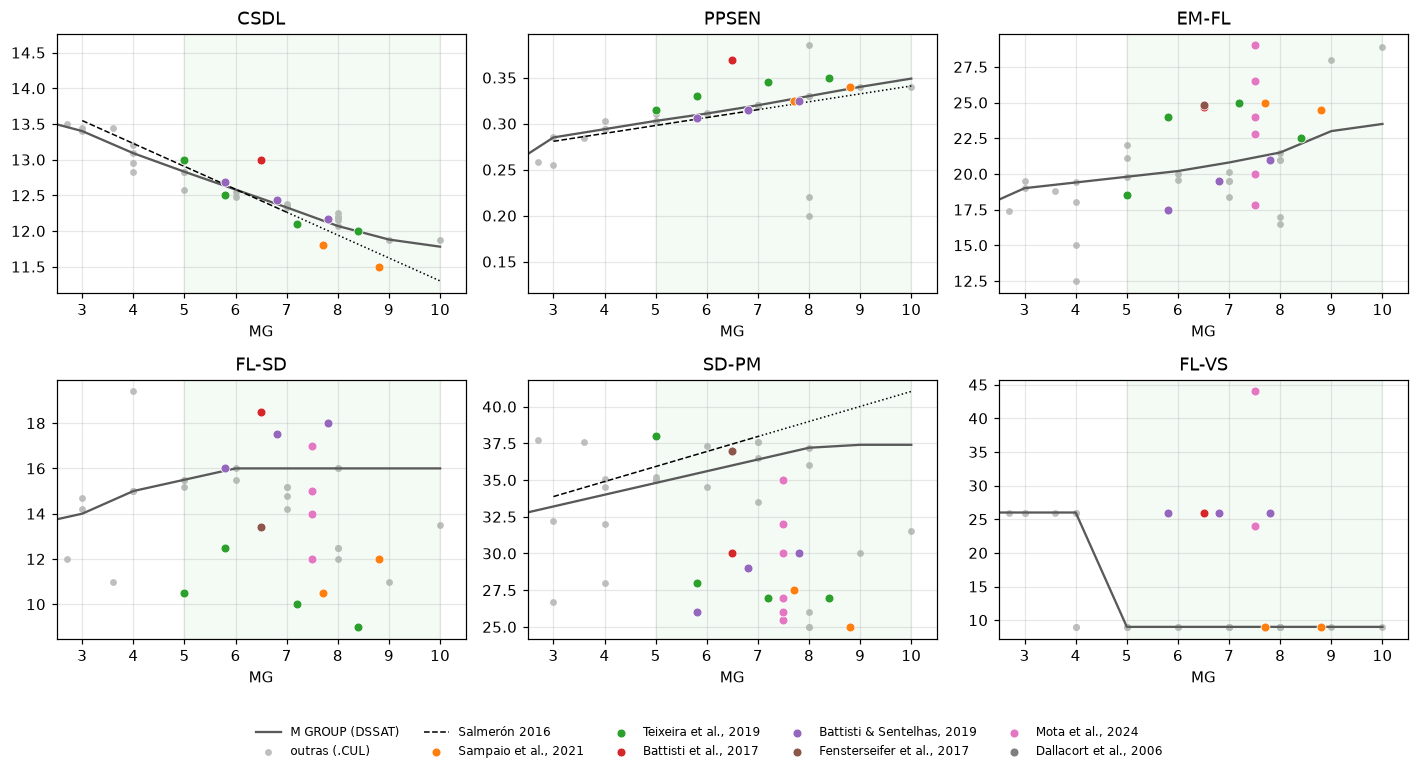

In [3]:
lit = ler_literatura()
fen = ["CSDL", "PPSEN", "EM-FL", "FL-SD", "SD-PM", "FL-VS"]
# Salmerón & Purcell (2016), EUA, indeterminadas: equações 3–5
SALMERON = {"CSDL": (-0.321, 14.51), "PPSEN": (0.0086, 0.255), "SD-PM": (1.023, 30.805)}
fig, axs = plt.subplots(2, 3, figsize=(13, 7))
gm = gen[gen["GENERICO"] & gen["VAR-NAME"].str.match(r"M GROUP\s+\d+$")].sort_values("MG")
outros = gen[~gen["GENERICO"]]
fontes = lit["fonte"].str.split(" \\(").str[0].unique()
cores = dict(zip(fontes, plt.cm.tab10.colors[1:]))
for ax, c in zip(axs.flat, fen):
    ax.plot(gm["MG"], gm[c], "-", color="0.35", lw=1.5, label="M GROUP (DSSAT)")
    ax.scatter(outros["MG"], outros[c], color="0.75", s=12, label="outras (.CUL)")
    if c in SALMERON:
        a, b = SALMERON[c]
        for x, ls in [(np.array([3, 7]), "--"), (np.array([7, 10]), ":")]:   # faixa estudada / extrapolação
            ax.plot(x, a * x + b, ls, color="k", lw=1, label="Salmerón 2016" if ls == "--" else None)
    for f in fontes:
        sub = lit[lit["fonte"].str.startswith(f)]
        ax.scatter(sub["MG"], sub[c], color=cores[f], s=34, zorder=3, edgecolor="w", lw=0.5, label=f)
    ax.axvspan(5, 10, color="tab:green", alpha=0.05)
    ax.set_xlim(2.5, 10.5); ax.set_title(c); ax.set_xlabel("MG")
h, l = axs.flat[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=5, fontsize=8, frameon=False)
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(RAIZ / "resultados" / "01_fenologia_vs_mg.png", bbox_inches="tight")

## Faixas propostas

In [4]:
faixas = calcular_faixas()
faixas.to_csv(RAIZ / "resultados" / "01_faixas_coeficientes.csv")
faixas.round(3)

,classe,arquivo,min,max,dssat_min,dssat_max,cul_mg_min,cul_mg_max,lit_min,lit_max,n_literatura,amplitude_rel
coef,,,,,,,,,,,,
CSDL,P,CUL,11.500,14.600,11.780,14.600,11.500,12.830,11.500,13.000,14,0.238
PPSEN,P,CUL,0.129,0.385,0.129,0.385,0.200,0.385,0.303,0.369,14,0.996
EM-FL,P,CUL,9.000,30.000,9.000,28.900,16.500,28.900,17.500,30.000,21,1.077
FL-SD,P,CUL,9.000,22.000,11.000,22.000,10.500,16.000,9.000,18.500,21,0.839
SD-PM,P,CUL,22.000,38.000,22.000,37.700,25.000,37.600,25.000,38.000,21,0.533
LFMAX,G,CUL,0.930,1.430,1.000,1.400,1.000,1.200,0.930,1.430,21,0.424
SLAVR,G,CUL,300.000,480.000,300.000,400.000,300.000,400.000,300.000,480.000,21,0.462
SIZLF,G,CUL,137.000,340.000,137.000,230.000,137.000,230.000,140.000,340.000,21,0.851
WTPSD,G,CUL,0.115,0.210,0.150,0.190,0.150,0.180,0.115,0.210,21,0.585


### Fora dos limites do DSSAT

Valores brasileiros abaixo do `MINIMA` ou acima do `MAXIMA` indicam que as faixas padrão do GENCALC/GLUE são estreitas demais para cultivares tropicais.

In [5]:
fora = faixas[(faixas["lit_min"] < faixas["dssat_min"]) | (faixas["lit_max"] > faixas["dssat_max"])]
fora[["dssat_min", "dssat_max", "lit_min", "lit_max"]]

,dssat_min,dssat_max,lit_min,lit_max
coef,,,,
CSDL,11.78,14.60,11.500,13.00
EM-FL,9.00,28.90,17.500,30.00
FL-SD,11.00,22.00,9.000,18.50
SD-PM,22.00,37.70,25.000,38.00
LFMAX,1.00,1.40,0.930,1.43
SLAVR,300.00,400.00,300.000,480.00
SIZLF,137.00,230.00,140.000,340.00
WTPSD,0.15,0.19,0.115,0.21
SFDUR,17.00,25.50,12.000,26.00


## Próximos passos

- Completar `coeficientes_literatura.csv` com os coeficientes dos trabalhos brasileiros (ver README) e rodar de novo este notebook.
- Etapa 02: escolher os locais (gradiente de latitude e regime hídrico) e rodar Morris com estas faixas.